[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/HesusG/dammg-supervisado/blob/main/notebooks/demos/D5_ganancia_informacion.ipynb)

# D5 · Ganancia de información = reducción de entropía; Gini vs entropía

*DAMMG · Módulo VI · Aprendizaje supervisado · FC-UNAM*

**Recuerden (Mód II).** $H(Y)=-\sum_k p_k\log_2 p_k$; $I(Y;S)=H(Y)-H(Y\mid S)\ge 0$.

**Supuestos.** Probabilidades = frecuencias en el nodo; cortes binarios; construcción voraz (un corte a la vez). Contraejemplo: XOR, donde ningún corte individual gana información.

**La idea.** $IG=H(\text{padre})-\sum_h \frac{n_h}{n}H(\text{hijo}_h)$. Movemos el umbral sobre la temperatura (datos sintéticos tipo MiBici: "¿demanda alta?") y comparamos la ganancia en entropía con la reducción de Gini.

La derivación completa está en `anexos/derivaciones.pdf`.

In [1]:
%matplotlib inline
import sys, pathlib
# dammg_utils vive en notebooks/ (en Colab se descarga junto al notebook)
for p in (pathlib.Path("..").resolve(), pathlib.Path(".").resolve()):
    if (p / "dammg_utils.py").exists() and str(p) not in sys.path:
        sys.path.insert(0, str(p))
import numpy as np
import matplotlib.pyplot as plt
from dammg_utils import estilo_dammg, COLORES
estilo_dammg()
C = COLORES
np.set_printoptions(precision=4, suppress=True)

## Parámetros
Si los controles no aparecen (por ejemplo, en el PDF), cambien el valor aquí y ejecuten de nuevo.

In [2]:
# Parámetro del ¿qué pasa si...?
UMBRAL = 18.0   # °C: los ejemplos con temperatura <= UMBRAL van al hijo izquierdo

## La identidad, con números

mejor umbral por IG: 21.82 °C | por Gini: 21.82 °C | sklearn (entropy): 21.85 °C
XOR: ganancia del primer corte = 0.0
padre [226 174]  H = 0.988 bits, Gini = 0.492
izq [176   6]  H = 0.209   der [ 50 168]  H = 0.777
IG = 0.469 bits   reducción de Gini = 0.270


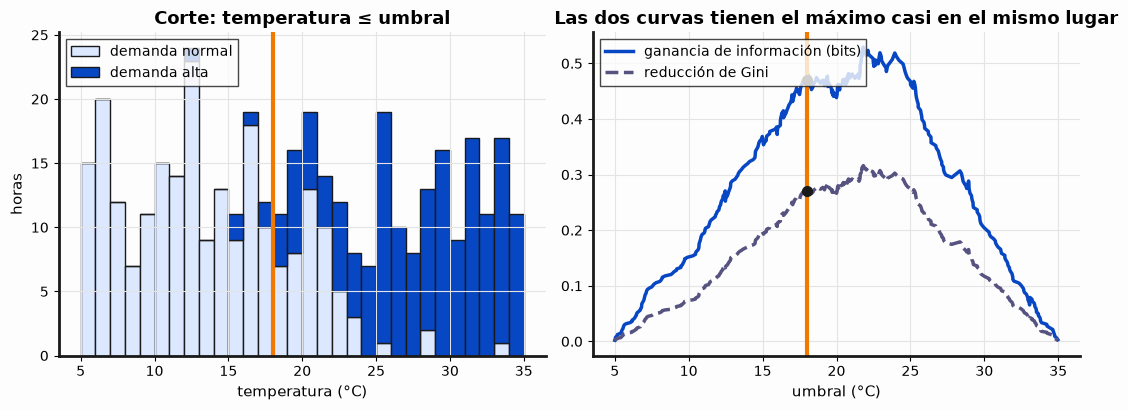

In [3]:
from sklearn.tree import DecisionTreeClassifier
from dammg_utils import entropia, gini, ganancia_info

rng = np.random.default_rng(5)
m = 400
temp = rng.uniform(5, 35, size=m)
p_alta = 1 / (1 + np.exp(-(temp - 22) / 2.5))
alta = (rng.random(m) < p_alta).astype(int)
conteo = lambda mask: np.bincount(alta[mask], minlength=2)

ts = np.unique(temp)[:-1]
IG = np.array([ganancia_info(conteo(np.ones(m, bool)), conteo(temp <= t), conteo(temp > t)) for t in ts])
GG = np.array([ganancia_info(conteo(np.ones(m, bool)), conteo(temp <= t), conteo(temp > t), gini) for t in ts])
assert (IG >= -1e-12).all() and (GG >= -1e-12).all()      # Jensen: nunca negativa
arbol = DecisionTreeClassifier(max_depth=1, criterion="entropy").fit(temp[:, None], alta)
print(f"mejor umbral por IG: {ts[IG.argmax()]:.2f} °C | por Gini: {ts[GG.argmax()]:.2f} °C | sklearn (entropy): {arbol.tree_.threshold[0]:.2f} °C")
q = np.linspace(1e-6, 1 - 1e-6, 1000)
assert np.all(-(q * np.log(q) + (1 - q) * np.log(1 - q)) >= 2 * q * (1 - q) - 1e-12)   # H_nats ≥ Gini
xor = ganancia_info([2, 2], [1, 1], [1, 1])
print(f"XOR: ganancia del primer corte = {xor}")

def demo(umbral=UMBRAL):
    izq, der = conteo(temp <= umbral), conteo(temp > umbral)
    padre = conteo(np.ones(m, bool))
    ig, gg = ganancia_info(padre, izq, der), ganancia_info(padre, izq, der, gini)
    print(f"padre {padre}  H = {entropia(padre):.3f} bits, Gini = {gini(padre):.3f}")
    print(f"izq {izq}  H = {entropia(izq):.3f}   der {der}  H = {entropia(der):.3f}")
    print(f"IG = {ig:.3f} bits   reducción de Gini = {gg:.3f}")
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
    bins = np.linspace(5, 35, 31)
    ax[0].hist([temp[alta == 0], temp[alta == 1]], bins=bins, stacked=True, color=[C["datos"], C["w"]],
               edgecolor=C["tinta"], linewidth=1, label=["demanda normal", "demanda alta"])
    ax[0].axvline(umbral, color=C["lambda"], linewidth=3)
    ax[0].set(xlabel="temperatura (°C)", ylabel="horas", title="Corte: temperatura ≤ umbral")
    ax[0].legend(loc="upper left")
    ax[1].plot(ts, IG, color=C["w"], label="ganancia de información (bits)")
    ax[1].plot(ts, GG, color=C["b"], linestyle="--", label="reducción de Gini")
    ax[1].axvline(umbral, color=C["lambda"], linewidth=3)
    ax[1].scatter([umbral, umbral], [ig, gg], color=C["tinta"], zorder=4)
    ax[1].set(xlabel="umbral (°C)", title="Las dos curvas tienen el máximo casi en el mismo lugar")
    ax[1].legend(loc="upper left")
    fig.tight_layout(); plt.show()

demo()

**¿Qué pasa si…?** Predigan: si ponen el umbral en 6 °C (casi todo al hijo derecho), ¿cuánto vale la ganancia? ¿Puede ser negativa?

Respuesta esperada: casi cero, porque el hijo grande se parece al padre. Nunca es negativa: la entropía es cóncava (Jensen). Gini y entropía eligen casi el mismo umbral.

In [4]:
# ¿Qué pasa si...? Muevan el control. Sin ipywidgets: cambien el parámetro arriba y vuelvan a ejecutar.
try:
    import ipywidgets as W
    W.interact(demo, umbral=W.FloatSlider(value=UMBRAL, min=6, max=34, step=0.5, description='umbral °C', continuous_update=False))
except ImportError:
    print('ipywidgets no está instalado: usen la celda de parámetros.')